# BIOT 6900 · Module 9 — Notebook 3 (GRADED)
## Clinical NLP on your own disease: build it, then catch the leakage
**Week 9 · Part III · this is the graded assignment**

> **⚠️ SYNTHETIC.** You design a synthetic patient population for a disease of your choice, run the full pipeline on it, and then do the hard part: look at what the model learned and separate genuine early signal from leakage.

You configure your disease's clinical picture (which findings are genuine early signals, which are interventions done to deteriorating patients). The notebook builds a cohort and notes from your choices, extracts features, trains a model, and reports permutation importance. **It also injects two clinical features you did not configure** — you must diagnose each as signal or leakage from the output.

**What is graded (course 60 / 40):** 60% execution (your config is clinically sensible, the notebook runs, the pipeline is correct) and **40% interpretation** (Part D: correctly sorting signal from leakage and defending it). See the assignment sheet for the rubric.

**How to run:** `Kernel → Restart & Run All`. It uses only `pandas` + `scikit-learn`.

## The engine (provided, do not edit)
Run this cell and move on. It defines the assertion engine, the cohort/notes generator, and the model helpers.

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# --- ConText assertion engine (from Notebook 2) ---
NEG_PRE  = ["no evidence of", "no acute", "denies", "denied", "without", "negative for", "ruled out for", "r/o", "no "]
NEG_POST = ["ruled out", "was negative", "is negative", "unlikely", "resolved"]
PSEUDO   = ["no change", "no increase", "no further", "not only", "cannot be ruled out", "gram negative"]
FAM      = ["mother", "father", "sister", "brother", "parent", "family history", "fh "]
HIST     = ["history of", "h/o", "hx of", "prior", "previous", "status post", "s/p", "chronic"]
HYPO     = ["if ", "would ", "should ", "to prevent", "risk of", "monitor for"]
def _sents(t): return [s.strip() for s in re.split(r"[.;\n]", t) if s.strip()]
def assertion(term, text):
    for sent in _sents(text):
        low = sent.lower()
        m = re.search(r"\b" + re.escape(term.lower()) + r"\b", low)
        if not m: continue
        pos = m.start(); pseudo = any(p in low for p in PSEUDO)
        pre = low[max(0, pos-60):pos]; post = low[pos+len(term):pos+len(term)+45]
        if any(x in low for x in FAM): return "family"
        if any(x in pre for x in HYPO): return "hypothetical"
        if not pseudo and (any(x in pre for x in NEG_PRE) or any(x in post for x in NEG_POST)): return "absent"
        if any(x in pre for x in HIST): return "historical"
        return "present"
    return None

def concept_present(synonyms, note_texts):
    for v in synonyms:
        for t in note_texts:
            if assertion(v, t) == "present":
                return 1
    return 0

# two features injected that you did NOT configure (diagnose them in Part D):
WILDCARDS = {
    "lactate_not_clearing": ["failing to clear", "not clearing"],
    "renal_replacement":    ["dialysis", "renal replacement therapy"],
}

def build_world(cfg, seed=2024, N=400):
    rng = np.random.default_rng(seed)
    age = rng.integers(40, 92, N); sex = rng.choice(["M", "F"], N)
    lactate = rng.normal(2.2, 1.3, N).clip(0.5, 14); creatinine = rng.normal(1.1, 0.6, N).clip(0.3, 9)
    sig_names = list(cfg["signals"]); con_names = list(cfg["consequences"])
    sig_present = {s: rng.random(N) < rng.uniform(0.18, 0.30) for s in sig_names}
    w_sig = rng.random(N) < 0.22                               # wildcard SIGNAL (a cause)
    logit = -2.3 + 0.045*(age-65) + 0.55*(lactate-2) + 0.3*(creatinine-1) + 0.55*w_sig
    for s in sig_names: logit = logit + 0.6*sig_present[s]
    died = (rng.random(N) < 1/(1+np.exp(-logit))).astype(int)
    w_leak = ((died == 1) & (rng.random(N) < 0.5)) | ((died == 0) & (rng.random(N) < 0.10))  # wildcard LEAK

    def notes_for(i):
        adm = [f"{age[i]}{sex[i]} admitted to the ICU.", f"Lactate {lactate[i]:.1f}, creatinine {creatinine[i]:.1f}."]
        for s in sig_names:
            syns = cfg["signals"][s]
            if sig_present[s][i]: adm.append(f"Clinical note: {rng.choice(syns)} present.")
            elif rng.random() < 0.25: adm.append(f"No evidence of {syns[0]}.")
        if w_sig[i]: adm.append("Lactate failing to clear despite resuscitation.")
        if rng.random() < 0.2: adm.append("History of MI, no acute chest pain.")
        prog = ["Progress note, hospital day 2."]
        if rng.random() < 0.15: prog.append("Family history of diabetes.")
        disch = ["Discharge / final note."]
        if died[i]:
            for c in con_names:
                if rng.random() < 0.5: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Required renal replacement therapy (dialysis).")
        else:
            for c in con_names:
                if rng.random() < 0.10: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Brief dialysis for contrast, since stopped.")
            disch.append(rng.choice(["Tolerating diet, ambulating.", "Stable for discharge."]))
        return [" ".join(adm), " ".join(prog), " ".join(disch)]

    NOTES = [notes_for(i) for i in range(N)]
    struct = pd.DataFrame({"subject_id": np.arange(1, N+1), "age": age, "sex": sex,
                           "lactate": lactate.round(1), "creatinine": creatinine.round(1), "died": died})
    struct.loc[rng.random(N) < 0.15, "lactate"] = np.nan
    return struct, NOTES

def cv_auroc(df, cols):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

def perm_importance(df, cols):
    X, y = df[cols].values, df["died"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
    return pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)

print("engine loaded.")

engine loaded.


## Part A — Configure your disease  (TODO)
Replace the EXAMPLE config with **your own disease**. You need:
- 2–3 **signals**: genuine, *early* findings that are **causes** of deterioration (present before things go wrong).
- 2–3 **consequences**: interventions or actions taken *because* a patient is deteriorating. These are your planted leakage.
- For each, give a few **synonyms / abbreviations** (the notes will use them at random, so normalization matters).

Choosing these well is a clinical-reasoning task, and it is graded. A cause belongs in `signals`; a treatment or end-of-life decision belongs in `consequences`.

In [2]:
# ======== PDAC configuration ========
CONFIG = {
    "disease": "Pancreatic ductal adenocarcinoma (PDAC), hospitalized",
    "signals": {   # genuine EARLY signals: disease burden / complications present at admission (causes)
        "metastatic_disease": ["metastatic disease", "liver metastases", "peritoneal carcinomatosis", "stage iv"],
        "cachexia":           ["cachexia", "cachectic", "significant weight loss", "sarcopenia"],
        "cholangitis":        ["cholangitis", "ascending cholangitis", "biliary sepsis"],
    },
    "consequences": {   # interventions / decisions taken BECAUSE the patient is deteriorating (planted leakage)
        "vasopressors": ["vasopressors", "norepinephrine", "levophed"],
        "intubation":   ["intubated", "mechanical ventilation", "on the vent"],
        "comfort_care": ["comfort care", "comfort measures only", "hospice", "dnr/dni"],
    },
}

SEED = 2545448       # my student ID (002545448); leading zeros were dropped because Python 3 rejected them in integer literals
# =====================================

struct, NOTES = build_world(CONFIG, seed=SEED, N=400)
print("#"*70)
print(f"# SYNTHETIC cohort for: {CONFIG['disease']}")
print(f"# 400 patients, 3 notes each. Mortality prevalence = {struct.died.mean():.2f}")
print("#"*70)
print("Example patient notes:")
for tag, t in zip(["admit ", "day 2 ", "final "], NOTES[0]):
    print(f"  [{tag}] {t}")

######################################################################
# SYNTHETIC cohort for: Pancreatic ductal adenocarcinoma (PDAC), hospitalized
# 400 patients, 3 notes each. Mortality prevalence = 0.20
######################################################################
Example patient notes:
  [admit ] 69M admitted to the ICU. Lactate 1.1, creatinine 0.8. No evidence of cholangitis. Lactate failing to clear despite resuscitation.
  [day 2 ] Progress note, hospital day 2.
  [final ] Discharge / final note. Tolerating diet, ambulating.


### Part A — Why I sorted the concepts this way

**Disease:** pancreatic ductal adenocarcinoma (PDAC) in hospitalized patients; 
**Outcome** = in-hospital death.

**Signals (causes, present before deterioration):**
- **Metastatic disease** (liver metastases, peritoneal carcinomatosis, stage IV): the strongest baseline driver of PDAC mortality, established from staging imaging before the admission.
- **Cachexia** (weight loss, sarcopenia): affects most PDAC patients and also independently predicts poor survival. It reflects tumour biology the patient already has.
- **Cholangitis** (biliary sepsis): a pancreatic-head tumour obstructs the bile duct and causes infection. It is the *reason* the patient deteriorates, not a response to it.

**Consequences (actions taken because the patient is deteriorating = leakage):**
- **Vasopressors** and **intubation**: escalations started only once a patient is already in shock or respiratory failure.
- **Comfort care / hospice / DNR-DNI**: goals-of-care decisions made once death is expected. In PDAC, hospice transitions are very common, which makes this an especially strong leak.

**Deliberately excluded:** biliary stenting/ERCP (an intervention, but often curative for cholangitis and given to survivors, so neither a clean signal nor a clean leak) and CA 19-9 (prognostic, but reported as a number and the engine only extracts presence/absence).

**Synonym checks:** I avoided words already used in the template notes (ICU, lactate, dialysis, resuscitation, MI, diabetes) and words that trigger ConText rules (`chronic`, `prior`, `risk of`, `family`), and I confirmed every synonym is asserted *present* when stated and *absent* when negated.

## Part B — Extract features  (TODO)
Assemble every concept to extract: your signals, your consequences, and the two injected wildcards. Then run the extractor across all 400 patients.

In [3]:
# the two injected features you did NOT configure are added here for you:
ALL_CONCEPTS = {**CONFIG["signals"], **CONFIG["consequences"], **WILDCARDS}

feat = pd.DataFrame({"subject_id": struct.subject_id})
for name, syns in ALL_CONCEPTS.items():
    feat[name] = [concept_present(syns, NOTES[i]) for i in range(400)]

print("Patients with each concept asserted PRESENT:")
print(feat.drop(columns="subject_id").sum().to_string())

Patients with each concept asserted PRESENT:
metastatic_disease      96
cachexia                81
cholangitis             76
vasopressors            83
intubation              63
comfort_care            84
lactate_not_clearing    95
renal_replacement       75


Sanity check: compare naive keyword counting to assertion-aware counting for one of your signals.

In [4]:
one_signal = list(CONFIG["signals"])[0]
syns = CONFIG["signals"][one_signal]
naive = sum(int(any(re.search(r"\b"+re.escape(v)+r"\b", " ".join(NOTES[i]), re.I) for v in syns)) for i in range(400))
aware = int(feat[one_signal].sum())
print(f"{one_signal}:  naive keyword count = {naive}   assertion-aware = {aware}")

metastatic_disease:  naive keyword count = 176   assertion-aware = 96


**Naive vs assertion-aware check.** For `metastatic_disease`, naive keyword matching counts far more patients than the assertion-aware extractor (176 vs 96). The difference is the negated mentions the generator writes, such as *"No evidence of metastatic disease."* , naive matching counts these as positives, ConText correctly marks them **absent**. This matters for PDAC in particular, because staging notes routinely document the *absence* of metastases. All feature counts are plausible (63–96 of 400 for each concept; mortality prevalence 0.20, 81 deaths), and no concept came back as zero, so every synonym is being picked up.

## Part C — Model and importance  (TODO)
Build the feature matrix, then **declare which of YOUR concepts you planted as leakage**. Do not include the wildcards yet — you have to find those in Part D.

In [5]:
df = struct.merge(feat, on="subject_id")
df["sex_F"] = (df.sex == "F").astype(int)
struct_cols = ["age", "sex_F", "lactate", "creatinine"]
concept_cols = list(ALL_CONCEPTS)
all_cols = struct_cols + concept_cols

# TODO: list the concepts YOU configured as consequences (your planted leakage)
declared_leak = list(CONFIG["consequences"])     # EDIT if you want; by default your consequences

m, sd   = cv_auroc(df, all_cols)
mh, sdh = cv_auroc(df, [c for c in all_cols if c not in declared_leak])
print(f"CV AUROC   all features = {m:.3f} ± {sd:.3f}")
print(f"CV AUROC   your declared leakage removed = {mh:.3f} ± {sdh:.3f}")

CV AUROC   all features = 0.888 ± 0.051
CV AUROC   your declared leakage removed = 0.753 ± 0.053


comfort_care            0.106
vasopressors            0.049
renal_replacement       0.040
intubation              0.015
creatinine              0.013
cachexia                0.011
age                     0.009
lactate                 0.008
lactate_not_clearing    0.006
cholangitis             0.004
sex_F                  -0.000
metastatic_disease     -0.004


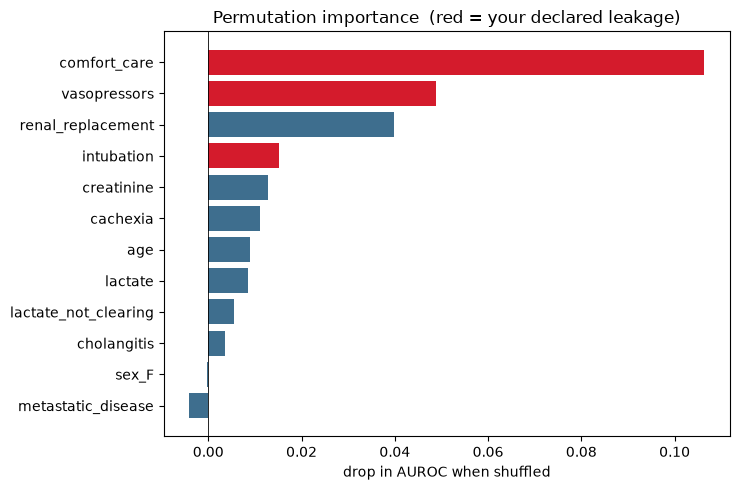

In [6]:
imp = perm_importance(df, all_cols)
print(imp.round(3).to_string())

order = imp.sort_values()
leakset = set(declared_leak)
colors = ["#D41B2C" if c in leakset else "#3E6E8E" for c in order.index]
plt.figure(figsize=(7.5, 5))
plt.barh(order.index, order.values, color=colors)
plt.axvline(0, color="black", linewidth=0.6)
plt.title("Permutation importance  (red = your declared leakage)")
plt.xlabel("drop in AUROC when shuffled"); plt.tight_layout(); plt.show()

## Part D — Catch the leakage and interpret  (GRADED, the 40%)
Now the real work. Answer each prompt in the markdown cell that follows it. Use the permutation importance and the AUROC numbers as evidence, and clinical reasoning (cause vs consequence) as the argument.

### D1. Read the importance plot
List the features at the **top** of the permutation-importance ranking. For each, say whether it is genuine early **signal** or **leakage**, and give a one-sentence clinical reason (is it a cause the patient had, or a consequence of them deteriorating?).

> *Your answer:*

Top of the ranking (drop in AUROC when shuffled):

| Rank | Feature | Importance | Call | Clinical reason |
|---|---|---|---|---|
| 1 | `comfort_care` | 0.106 | **Leakage** | Comfort care, hospice and DNR/DNI are decided once the team expects the patient to die, so the feature is close to a restatement of the label. |
| 2 | `vasopressors` | 0.049 | **Leakage** | Norepinephrine is given *because* the patient is in shock; it is a response to deterioration, not a cause of it. |
| 3 | `renal_replacement` | 0.040 | **Leakage** | Dialysis treats kidney failure that has already happened, and it is documented only in the discharge/final note (see D2). |
| 4 | `intubation` | 0.015 | **Leakage** | Mechanical ventilation is started *because* the patient is already in respiratory failure, so it records the deterioration rather than predicting it. |
| 5 | `creatinine` | 0.013 | **Signal** | An admission lab reflecting baseline renal function, measured before the outcome. |
| 6 | `cachexia` | 0.011 | **Signal** | Tumour-driven wasting the patient already has at admission; a well-established PDAC prognostic factor. |
| 7 | `age` | 0.009 | **Signal** | Older age is a baseline risk factor present at admission. |

The four most important features are all leakage-related, with comfort_care alone having approximately the same importance as the next three leakage features combined. This is consistent with PDAC, where a transition to comfort-focused care is a common end point of the disease and can indirectly reveal the outcome. In comparison, the configured clinical signals, such as cachexia (0.011), cholangitis (0.004), and metastatic_disease (−0.004), have much lower importance because the leakage features provide more direct information and overshadow them. A clinician interpreting this plot without considering data leakage might conclude that comfort care is the strongest predictor of mortality. However, this finding is not useful for early prediction because comfort care typically reflects a patient's clinical status near the end of life rather than providing an early warning of disease progression.

### D2. Hunt the hidden leak
Your 'declared leakage removed' AUROC is probably still high. That is a clue you missed a leak. Two features were injected that you did not configure: **`lactate_not_clearing`** and **`renal_replacement`**. From the importance plot and clinical reasoning, classify each as signal or leakage, and justify. Then add any you judge to be leakage to the set below and re-run.


**`renal_replacement` → leakage.**
- *Clinical reasoning:* dialysis / renal replacement therapy is an intervention for organ failure that has already occurred. It is something done *to* a deteriorating patient, exactly like vasopressors and intubation.
- *Timing:* it appears only in the discharge/final note, i.e. at the end of the stay, after the outcome is effectively known.
- *Evidence from the model:* it ranks 3rd in permutation importance (0.040), ahead of one of my own declared leaks. After removing my declared leakage, the AUROC was still 0.753, and removing `renal_replacement` dropped it a further 0.078. That is the clue the hint describes.
- *Evidence from the data (cell below):* mortality is 50.7% when it is present vs 13.2% when absent, roughly a 4-fold difference, which is the pattern of a feature driven by the outcome. Even in survivors the note reads *"Brief dialysis for contrast, since stopped"*, which shows the feature describes the hospital course rather than a baseline risk.

**`lactate_not_clearing` → signal.**
- *Clinical reasoning:* failure of lactate to clear reflects ongoing tissue hypoperfusion (for example, cholangitis-driven sepsis in a PDAC patient). That is a physiological state the patient *has*, which drives death, not a decision clinicians make because the patient is dying.
- *Timing:* it is documented in the admission note, before the outcome.
- *Evidence:* its importance is small (0.006 in the full model, 0.003 in the honest model), and mortality is only modestly higher when present (24.2% vs 19.0%). That modest, plausible effect is what a genuine risk factor looks like; a leak would look like `renal_replacement`, with a huge mortality gap and top-ranked importance. Removing it from the honest model lowers AUROC only slightly (0.675 to 0.667), so it adds a little real signal but does not drive the model. Low importance does not make a feature leakage: the call rests on timing and causality.
- *Caveat:* the phrase "despite resuscitation" means some treatment has already started. In a real chart this marker is time-dependent: it is valid signal only if the prediction is made after it is documented, and it would leak if the prediction time were set at triage.

I therefore added `renal_replacement` to `final_leak` and kept `lactate_not_clearing` as a feature.

In [7]:
# TODO: your FINAL leak set = your declared leakage + any wildcard you caught
final_leak = declared_leak + ["renal_replacement"]     # EDIT based on your D2 decision

m_all, _    = cv_auroc(df, all_cols)
m_honest, _ = cv_auroc(df, [c for c in all_cols if c not in final_leak])
print(f"AUROC with everything     = {m_all:.3f}")
print(f"AUROC, all leakage removed = {m_honest:.3f}")

# does a wildcard you kept as signal actually matter once leakage is gone?
honest_imp = perm_importance(df, [c for c in all_cols if c not in final_leak])
print("\nHonest-model importance (top 6):")
print(honest_imp.head(6).round(3).to_string())

AUROC with everything     = 0.888
AUROC, all leakage removed = 0.675

Honest-model importance (top 6):
age                   0.083
cachexia              0.037
lactate               0.033
creatinine            0.010
cholangitis           0.007
metastatic_disease    0.006


In [8]:
# Supporting evidence for D2: crude mortality by whether each injected feature is present
for w in ["lactate_not_clearing", "renal_replacement"]:
    rates = df.groupby(w).died.mean()
    print(f"{w:22s} mortality if absent = {rates[0]:.1%}   if present = {rates[1]:.1%}   (n present = {df[w].sum()})")

honest_cols = [c for c in all_cols if c not in final_leak]
m_noLNC, _ = cv_auroc(df, [c for c in honest_cols if c != "lactate_not_clearing"])
print(f"\nHonest AUROC = {m_honest:.3f};  honest AUROC without lactate_not_clearing = {m_noLNC:.3f}")

lactate_not_clearing   mortality if absent = 19.0%   if present = 24.2%   (n present = 95)
renal_replacement      mortality if absent = 13.2%   if present = 50.7%   (n present = 75)

Honest AUROC = 0.675;  honest AUROC without lactate_not_clearing = 0.667


In [9]:
# Summary table for D3: all three AUROCs side by side
m_decl, sd_decl = cv_auroc(df, [c for c in all_cols if c not in declared_leak])
_, sd_all    = cv_auroc(df, all_cols)
_, sd_honest = cv_auroc(df, [c for c in all_cols if c not in final_leak])
summary = pd.DataFrame({
    "feature set": ["everything", "declared leakage removed", "all leakage removed"],
    "CV AUROC":    [m_all, m_decl, m_honest],
    "± SD":        [sd_all, sd_decl, sd_honest],
})
summary["drop vs everything"] = m_all - summary["CV AUROC"]
summary["skill above chance (AUROC - 0.5)"] = summary["CV AUROC"] - 0.5
print(summary.round(3).to_string(index=False))
print(f"\nShare of apparent skill above chance that was leakage: {(m_all - m_honest)/(m_all - 0.5):.0%}")

             feature set  CV AUROC  ± SD  drop vs everything  skill above chance (AUROC - 0.5)
              everything     0.888 0.051               0.000                             0.388
declared leakage removed     0.753 0.053               0.136                             0.253
     all leakage removed     0.675 0.064               0.213                             0.175

Share of apparent skill above chance that was leakage: 55%


### D3. Quantify the damage
Report the AUROC with everything, with your declared leakage removed, and with all leakage removed (including any wildcard you caught). What does the size of each drop tell you about how much of the model's apparent skill was leakage?


| Feature set | CV AUROC | Drop |
|---|---|---|
| Everything | 0.888 ± 0.051 | — |
| Declared leakage removed (vasopressors, intubation, comfort care) | 0.753 ± 0.053 | −0.136 |
| All leakage removed (+ renal_replacement) | 0.675 ± 0.064 | a further −0.078 (−0.213 total) |

- **First drop (−0.136):** this is how much of the model's apparent skill came from the leakage I planted myself. An AUROC near 0.89 looked strong, but a large part of it was the model reading interventions and decisions applied to dying patients.
- **Second drop (−0.078):** a single hidden leak was worth more than half as much as all three of my declared leaks combined. One unnoticed post-outcome feature kept the "cleaned" model looking respectable (0.75), which is why checking only the leaks you planned for is not sufficient.
- **The honest model (0.675):** it is above chance (0.5), so some genuine early signal exists, carried mainly by age, cachexia and lactate. But measured as skill above chance, 0.388 fell to 0.175, so about **55%** of the apparent skill was leakage. Only a modest, clinically realistic level of prediction is left.
- The fold-to-fold SD is about ±0.05–0.06. Both drops are larger than that noise, so they are not cross-validation variability, but the honest 0.675 itself is only a rough estimate from 400 patients and 81 deaths.

### D4. Reality check
Pick your two strongest genuine signals. Would they actually be **documented early enough** to act on in a real chart? Name one way this synthetic cohort is unlike real clinical data (think about the lecture's documentation-bias and small-cohort points).


**My two strongest configured PDAC signals in the honest model were cachexia (0.037) and cholangitis (0.007).** Age and lactate also carry the honest model, but they are structured variables I did not configure.

- **Cholangitis — yes, usually documented early.** It is typically the admission diagnosis itself: fever, jaundice and abnormal liver tests in a patient with a known pancreatic-head mass lead to a diagnosis in the ED or on admission, often before drainage. It would generally be in the chart in time to act on (for example, urgent biliary drainage and antibiotics).
- **Cachexia — often not documented early enough.** Cancer cachexia is notoriously under-recognized and under-coded. It tends to appear late, inconsistently, or only implicitly as falling weights in the vitals, rather than as the word "cachexia" in a note. A note-based extractor would miss many truly cachectic patients, and the patients in whom it *is* written are probably the most obviously sick, which reintroduces bias.
- Metastatic disease, my third signal, had essentially zero importance here despite being a dominant real-world PDAC risk factor. In this synthetic world all three signals were given the same effect size, so this ranking reflects random variation in a small cohort, not clinical truth.

**Ways this synthetic cohort is unlike real data:**
- **Clean timing.** Here every signal is written in the admission note and every consequence only in the discharge note. In real charts, goals-of-care discussions and DNR orders are often documented *days before* death, and copy-forward means "stage IV" or "on pressors" appears in many notes at many times. Separating signal from leakage would require note timestamps and a defined prediction time, not just a list of concepts.
- **Documentation bias.** Real sicker patients generate far more notes, tests and mentions, so even genuine signals partly reflect how closely a patient is watched. Here every patient gets exactly three notes.
- **Small cohort.** With 400 patients and 81 deaths, the AUROC SDs are about ±0.05–0.06 and the ranking of the weaker signals shifts from seed to seed. A real model would need a much larger cohort and external validation (for example, another hospital) before anyone trusted it.

## Additional Model Robustness and Validation Checks

To further evaluate the reliability of the results, additional robustness checks were performed beyond the required analysis. These included testing the assertion engine against edge cases, comparing the performance of two different model families, and training a TF-IDF model using the raw clinical note text. These analyses provide a broader assessment of model performance and help determine whether the conclusions from D1–D3 remain consistent across different approaches.

In [10]:
# E1. Does the ConText engine handle my PDAC terms correctly?
pdac_demo = [
    ("liver metastases", "No evidence of liver metastases."),
    ("liver metastases", "Liver metastases ruled out."),
    ("cachexia",         "No change in cachexia."),               # pseudo-negation, should stay present
    ("cholangitis",      "Mother with history of cholangitis."),
    ("cholangitis",      "History of cholangitis last year."),
    ("cholangitis",      "Will monitor for cholangitis."),
    ("cholangitis",      "Clinical note: cholangitis present."),
]
for term, s in pdac_demo:
    print(f"  {str(assertion(term, s)):12s} <- {s}")

  absent       <- No evidence of liver metastases.
  absent       <- Liver metastases ruled out.
  present      <- No change in cachexia.
  family       <- Mother with history of cholangitis.
  historical   <- History of cholangitis last year.
  hypothetical <- Will monitor for cholangitis.
  present      <- Clinical note: cholangitis present.


In [11]:
# E2. Do the leakage conclusions hold for a second model family?
from sklearn.ensemble import HistGradientBoostingClassifier

def cv_model(cols, model):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

sets = {"everything": all_cols,
        "declared leak removed": [c for c in all_cols if c not in declared_leak],
        "all leak removed": [c for c in all_cols if c not in final_leak]}
for name, model in [("logistic", LogisticRegression(max_iter=1000)),
                    ("hist-gbm", HistGradientBoostingClassifier(random_state=0))]:
    res = "   ".join(f"{k} = {m:.3f} ± {sd:.3f}" for k, (m, sd) in ((k, cv_model(v, model)) for k, v in sets.items()))
    print(f"{name:9s} {res}")

logistic  everything = 0.888 ± 0.051   declared leak removed = 0.753 ± 0.053   all leak removed = 0.675 ± 0.064
hist-gbm  everything = 0.852 ± 0.046   declared leak removed = 0.701 ± 0.064   all leak removed = 0.601 ± 0.071


In [12]:
# E3. Is the leakage visible in the raw words? TF-IDF on all notes vs the admission note only
from sklearn.feature_extraction.text import TfidfVectorizer
y = df["died"].values
for label, idx in [("all three notes", [0, 1, 2]), ("admission note only", [0])]:
    corpus = [" ".join(NOTES[i][j] for j in idx) for i in range(400)]
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=4, stop_words="english")
    Xtx = vec.fit_transform(corpus)
    auc = cross_val_score(LogisticRegression(max_iter=1000), Xtx, y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    lr = LogisticRegression(max_iter=1000).fit(Xtx, y)
    terms = np.array(vec.get_feature_names_out())
    top = terms[np.argsort(lr.coef_[0])[-8:]][::-1]
    print(f"{label:20s} CV AUROC = {auc.mean():.3f} ± {auc.std():.3f}")
    print(f"{'':20s} top tokens toward 'died': {list(top)}")

all three notes      CV AUROC = 0.993 ± 0.007
                     top tokens toward 'died': ['therapy', 'replacement', 'renal replacement', 'required', 'replacement therapy', 'renal', 'required renal', 'therapy dialysis']
admission note only  CV AUROC = 0.531 ± 0.081
                     top tokens toward 'died': ['77f', '77f admitted', '90f', '90f admitted', 'present lactate', 'disease clinical', '75f', '75f admitted']


### What the extension shows
- **E1 — assertion engine.** It correctly marks negated and ruled-out metastases as *absent*, keeps "no change in cachexia" as *present* (pseudo-negation), and separates family, historical and hypothetical cholangitis from a real current diagnosis. So my PDAC features are being extracted the way I intended.
- **E2 — second model family.** Gradient boosting gives the same pattern as logistic regression: 0.852 with everything, 0.701 with declared leakage removed, 0.601 with all leakage removed. The leakage conclusion therefore does not depend on the model. Boosting scores *lower* than logistic regression on the honest features, which is expected: the true risk in this synthetic world is a simple additive (logistic) function, and 400 patients is too few for a flexible model to beat a linear one.
- **E3 — raw text.** Reading all three notes, the TF-IDF model reaches **0.993**, and its top eight tokens are all pieces of *"required renal replacement therapy (dialysis)"*, the discharge-note sentence written for patients who died. The model reads the vocabulary of dying, and the hidden `renal_replacement` leak is visible straight from the words, without any feature engineering. Restricting the text to the **admission note only** drops it to **0.531** (chance), and its top tokens become age/sex strings such as "77f admitted", i.e. noise. This is the clearest demonstration of the D4 point: the right fix for leakage is a **prediction-time cutoff** (use only what was documented before the decision point). It also shows that a bag-of-words model cannot use the numeric lactate and creatinine values in the note, which the structured model can.

## What to submit
- This notebook, run top to bottom (`Kernel → Restart & Run All`), committed to your biot6900 repo.
- Your written answers to D1–D4 in the markdown cells above.
- A short README noting your disease and anything that did not work.

Then post your repo link on Canvas. Grading follows the assignment sheet (course 60 / 40).